# Schedule padding

**Hypotheses.** H1: flights with more padding arrive on time more often, with diminishing returns. H2: padding differs across airlines and times of day.

**Definitions (fixed before looking at results).**
- Block time: gate to gate. Scheduled = `crs_elapsed`, actual = `actual_elapsed`.
- Reference: median actual block time of each directional route (origin→destination), all airlines pooled, routes with 30+ flights.
- Padding = scheduled − reference, in minutes.
- On time: arrival delay under 15 minutes.

In [1]:
from pathlib import Path
import duckdb
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent
con = duckdb.connect()
con.execute(f"CREATE OR REPLACE VIEW flights AS SELECT * FROM read_parquet('{(ROOT / 'data' / 'parquet').as_posix()}/*.parquet')")
con.sql("SELECT count(*) AS n_flights FROM flights")

┌───────────┐
│ n_flights │
│   int64   │
├───────────┤
│    605844 │
└───────────┘

In [2]:
import logging
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

BRAND = {"black": "#0D0D0D", "yellow": "#F5C518", "white": "#FFFFFF", "grey": "#8C8C8C"}
TITLE_FONT = ["Space Grotesk", "Inter 18pt", "DejaVu Sans"]

plt.rcParams.update({
    "figure.facecolor": BRAND["black"], "axes.facecolor": BRAND["black"], "savefig.facecolor": BRAND["black"],
    "text.color": BRAND["white"], "axes.labelcolor": BRAND["grey"],
    "xtick.color": BRAND["grey"], "ytick.color": BRAND["grey"],
    "axes.edgecolor": "#2A2A2A", "grid.color": "#2A2A2A", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "font.sans-serif": ["Inter 18pt", "DejaVu Sans"], "font.family": "sans-serif", "font.size": 10.5,
})

In [3]:
con.execute("""
CREATE OR REPLACE VIEW blk AS
WITH f AS (
    SELECT carrier, origin, dest, crs_elapsed, actual_elapsed, arr_delay, crs_dep_hhmm
    FROM flights
    WHERE NOT cancelled AND NOT diverted
      AND actual_elapsed IS NOT NULL AND crs_elapsed IS NOT NULL AND arr_delay IS NOT NULL
),
r AS (
    SELECT origin, dest, count(*) AS n_route, median(actual_elapsed) AS ref_min
    FROM f
    GROUP BY origin, dest
    HAVING count(*) >= 30
)
SELECT f.*, r.n_route, r.ref_min, f.crs_elapsed - r.ref_min AS padding_min
FROM f JOIN r USING (origin, dest)
""")

In [4]:
con.sql("""
    SELECT
        count(*)                                                    AS n_flights,
        count(DISTINCT origin || '-' || dest)                       AS n_routes,
        round(100.0 * count(*) / (SELECT count(*) FROM flights WHERE NOT cancelled AND NOT diverted), 1) AS pct_of_operated,
        round(100.0 * avg((padding_min < 0)::INT), 1)               AS pct_tighter_than_typical,
        round(100.0 * avg((padding_min > 20)::INT), 1)              AS pct_over_20_min,
        quantile_cont(padding_min, [0.05, 0.25, 0.5, 0.75, 0.95])   AS quantiles
    FROM blk
""").df()

,n_flights,n_routes,pct_of_operated,pct_tighter_than_typical,pct_over_20_min,quantiles
0,584159,4389,97.1,10.1,2.2,"[-2.0, 3.0, 6.0, 10.0, 17.0]"


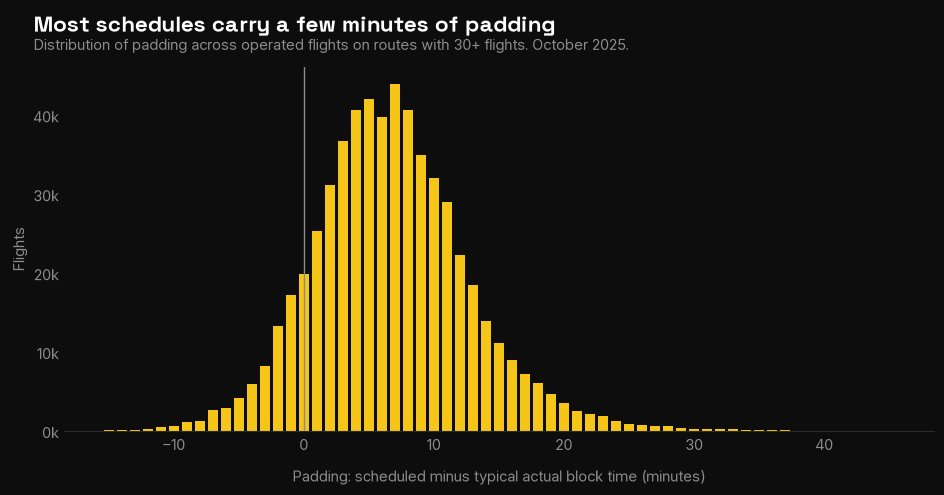

In [5]:
dist = con.sql("""
    SELECT round(padding_min)::INT AS padding, count(*) AS n
    FROM blk
    WHERE padding_min BETWEEN -15 AND 45
    GROUP BY 1 ORDER BY 1
""").df()

fig, ax = plt.subplots(figsize=(10, 5.2))
ax.grid(axis="x", visible=False)
ax.bar(dist["padding"], dist["n"], width=0.8, color=BRAND["yellow"])
ax.axvline(0, color=BRAND["grey"], linewidth=1)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
ax.tick_params(length=0)
ax.set_xlabel("Padding: scheduled minus typical actual block time (minutes)", labelpad=10)
ax.set_ylabel("Flights")

fig.text(0.07, 0.95, "Most schedules carry a few minutes of padding", fontsize=16, fontweight="bold",
         fontfamily=TITLE_FONT, ha="left", va="top")
fig.text(0.07, 0.90, "Distribution of padding across operated flights on routes with 30+ flights. October 2025.",
         fontsize=10.5, color=BRAND["grey"], ha="left", va="top")
fig.subplots_adjust(left=0.1, right=0.97, top=0.84, bottom=0.14)

fig.savefig(ROOT / "figures" / "padding_distribution.png", dpi=150)
plt.show()

### Findings

- The reference covers 584,159 flights (97.1% of operated flights) on 4,389 routes with 30+ flights.
- Median padding is 6 minutes; the middle half of flights sits between 3 and 10 minutes, and the 5th–95th percentile range is −2 to +17.
- Only 10.1% of flights are scheduled tighter than the typical actual block time of their route; 2.2% carry more than 20 minutes of padding.
- Padding is measured against the pooled median actual time, which already includes routine congestion on each route. It is padding relative to what usually happens, not relative to a theoretical minimum.

## Does padding buy punctuality? (H1)

Arrival delay is departure delay plus (actual − scheduled block time), so some link between padding and on-time arrival is mechanical. The question is the **shape**: how many on-time points each extra minute buys, and where the curve flattens.

Two cuts: (1) on-time rate by padding across all flights, and (2) within the same route, using each flight's padding minus the average padding of its route. The second removes differences between routes (length, congestion).

In [6]:
con.execute("""
CREATE OR REPLACE VIEW blk_w AS
SELECT *, padding_min - avg(padding_min) OVER (PARTITION BY origin, dest) AS padding_dev
FROM blk
""")

In [7]:
raw = con.sql("""
    SELECT round(padding_min)::INT AS pad, count(*) AS n, round(100.0 * avg((arr_delay < 15)::INT), 1) AS ontime_pct
    FROM blk
    WHERE padding_min BETWEEN -5 AND 25
    GROUP BY 1 HAVING count(*) >= 1000
    ORDER BY 1
""").df()

within = con.sql("""
    SELECT least(greatest(round(padding_dev / 2)::INT * 2, -10), 10) AS dev,
           count(*) AS n, round(100.0 * avg((arr_delay < 15)::INT), 1) AS ontime_pct
    FROM blk_w
    WHERE n_route >= 100
    GROUP BY 1
    ORDER BY 1
""").df()

display(raw.T)
display(within.T)

,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,24,25,26,27,28,29
pad,-5.0,-4.0,-3.0,-2.0,-1.0,0.0,1.0,2.0,3.0,4.0,...,15.0,16.0,17.0,18.0,19.0,20.0,21.0,22.0,23.0,24.0
n,4177.0,5973.0,8173.0,13301.0,17235.0,19917.0,25324.0,31131.0,36725.0,40653.0,...,11091.0,8982.0,7172.0,6055.0,4714.0,3528.0,2470.0,2191.0,1943.0,1217.0
ontime_pct,70.7,71.6,70.9,72.4,73.5,74.8,76.9,77.4,78.6,78.8,...,84.0,82.9,83.8,83.7,83.8,83.4,83.6,82.0,84.7,84.2


,0,1,2,3,4,5,6,7,8,9,10
dev,-10.0,-8.0,-6.0,-4.0,-2.0,0.0,2.0,4.0,6.0,8.0,10.0
n,10951.0,15884.0,31366.0,54511.0,81227.0,88026.0,64819.0,41362.0,24928.0,14545.0,20270.0
ontime_pct,74.4,75.5,75.8,77.2,79.1,79.9,80.0,80.0,80.4,80.7,80.2


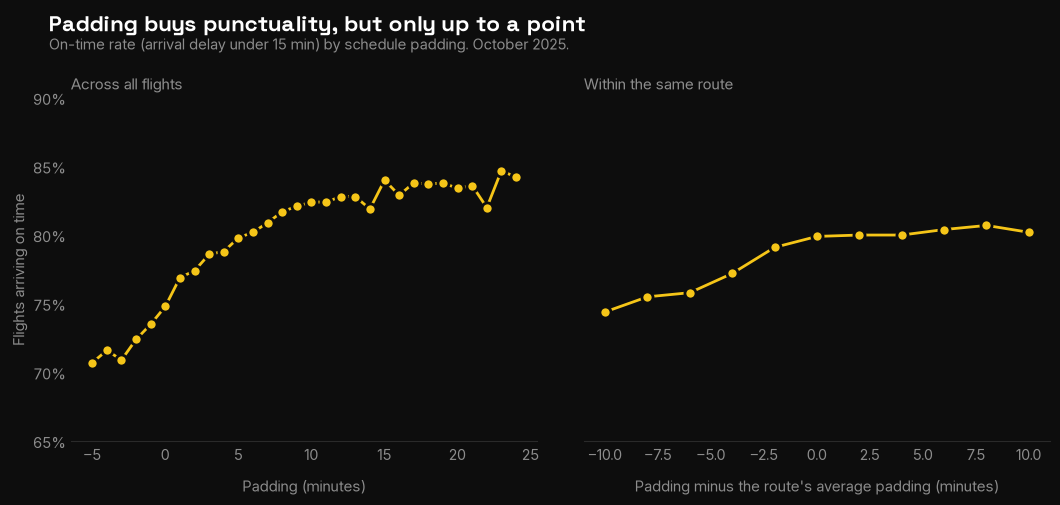

In [8]:
raw["ontime"] = raw["ontime_pct"]
within["ontime"] = within["ontime_pct"]

fig, axs = plt.subplots(1, 2, figsize=(11, 5.2), sharey=True)
for ax, d, x, xlabel in [(axs[0], raw, "pad", "Padding (minutes)"),
                         (axs[1], within, "dev", "Padding minus the route's average padding (minutes)")]:
    ax.grid(axis="x", visible=False)
    ax.plot(d[x], d["ontime"], color=BRAND["yellow"], linewidth=2, marker="o", markersize=8,
            markerfacecolor=BRAND["yellow"], markeredgecolor=BRAND["black"], markeredgewidth=2)
    ax.set_xlabel(xlabel, labelpad=10)
    ax.tick_params(length=0)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))

axs[0].set_ylim(65, 90)
axs[0].set_ylabel("Flights arriving on time")
axs[0].set_title("Across all flights", loc="left", fontsize=11, color=BRAND["grey"])
axs[1].set_title("Within the same route", loc="left", fontsize=11, color=BRAND["grey"])

fig.text(0.06, 0.97, "Padding buys punctuality, but only up to a point", fontsize=16, fontweight="bold",
         fontfamily=TITLE_FONT, ha="left", va="top")
fig.text(0.06, 0.92, "On-time rate (arrival delay under 15 min) by schedule padding. October 2025.",
         fontsize=10.5, color=BRAND["grey"], ha="left", va="top")
fig.subplots_adjust(left=0.08, right=0.97, top=0.80, bottom=0.14, wspace=0.1)

fig.savefig(ROOT / "figures" / "padding_ontime.png", dpi=150)
plt.show()

### Findings

- Across all flights, on-time rate rises from 70.7% at −5 min of padding to 82.4% at +10 min (about 0.8 points per minute), then flattens around 83–84% beyond +12 min.
- Within the same route the curve is asymmetric: flights scheduled 10 min tighter than their route's average padding arrive on time 74.4% of the time versus 79.9% at the average; flights scheduled looser than average gain almost nothing (80.7% at +8 min).
- Being tighter than the route norm costs punctuality, while extra padding beyond the norm buys little. Diminishing returns start at the route's usual padding.
- The within-route gradient is smaller than the global one, so part of the global slope reflects differences between routes (and their airlines and times of day) rather than padding itself. Magnitudes are not directly comparable because the x ranges differ; the shapes are.
- Part of the relationship is mechanical: arrival delay equals departure delay plus (actual − scheduled block time).

## How does padding vary? (H2)

Padding is measured against each route's own typical block time, so airline comparisons are already like-for-like on route. Two cuts: by airline (median and middle 50% of flights) and by scheduled departure hour (mean padding next to on-time rate).

In [9]:
airline_pad = con.sql("""
    SELECT carrier,
           count(*)                                         AS n,
           round(median(padding_min), 1)                    AS median_pad,
           round(quantile_cont(padding_min, 0.25), 1)       AS q1,
           round(quantile_cont(padding_min, 0.75), 1)       AS q3,
           round(100.0 * avg((arr_delay < 15)::INT), 1)     AS ontime_pct
    FROM blk
    GROUP BY carrier
    HAVING count(*) >= 2000
    ORDER BY median_pad DESC
""").df()
airline_pad

,carrier,n,median_pad,q1,q3,ontime_pct
0,F9,16333,11.0,7.0,15.0,77.6
1,OH,19801,8.0,3.0,12.5,80.9
2,AS,19574,7.0,3.0,11.0,80.0
3,AA,84539,7.0,3.0,11.0,76.8
4,OO,70176,7.0,4.0,11.0,82.7
5,NK,13315,6.5,3.0,10.0,80.6
6,B6,17297,6.0,2.0,12.0,74.5
7,DL,88904,6.0,3.0,9.0,84.0
8,WN,118952,6.0,3.0,9.0,77.3
9,UA,70682,6.0,2.0,10.0,80.4


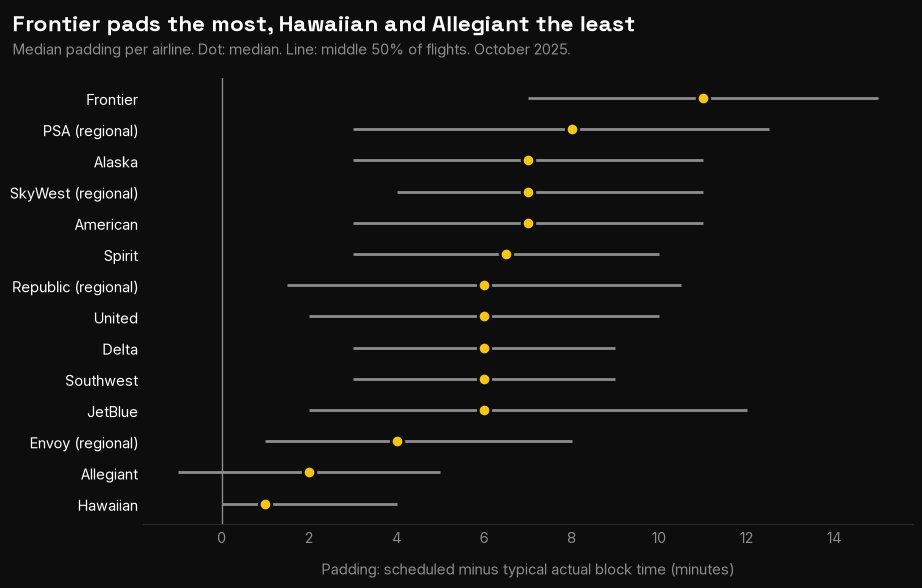

In [10]:
NAMES = {"AA": "American", "AS": "Alaska", "B6": "JetBlue", "DL": "Delta", "F9": "Frontier", "G4": "Allegiant",
         "HA": "Hawaiian", "MQ": "Envoy", "NK": "Spirit", "OH": "PSA", "OO": "SkyWest", "UA": "United",
         "WN": "Southwest", "YX": "Republic"}
REGIONAL = {"MQ", "OH", "OO", "YX"}

al = airline_pad.sort_values("median_pad").reset_index(drop=True)
labels = [f"{NAMES[c]}{' (regional)' if c in REGIONAL else ''}" for c in al["carrier"]]
y = np.arange(len(al))

fig, ax = plt.subplots(figsize=(10, 6.2))
ax.grid(axis="y", visible=False)
ax.axvline(0, color=BRAND["grey"], linewidth=1)
ax.hlines(y, al["q1"], al["q3"], color=BRAND["grey"], linewidth=2)
ax.plot(al["median_pad"], y, linestyle="none", marker="o", markersize=9, markerfacecolor=BRAND["yellow"],
        markeredgecolor=BRAND["black"], markeredgewidth=2)
ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.tick_params(axis="y", labelcolor=BRAND["white"], length=0)
ax.tick_params(axis="x", length=0)
ax.set_xlabel("Padding: scheduled minus typical actual block time (minutes)", labelpad=10)

fig.text(0.07, 0.95, "Frontier pads the most, Hawaiian and Allegiant the least", fontsize=16, fontweight="bold",
         fontfamily=TITLE_FONT, ha="left", va="top")
fig.text(0.07, 0.90, "Median padding per airline. Dot: median. Line: middle 50% of flights. October 2025.",
         fontsize=10.5, color=BRAND["grey"], ha="left", va="top")
fig.subplots_adjust(left=0.2, right=0.97, top=0.84, bottom=0.12)

fig.savefig(ROOT / "figures" / "padding_by_airline.png", dpi=150)
plt.show()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
hr,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0,13.0,14.0,15.0,16.0,17.0,18.0,19.0,20.0,21.0,22.0,23.0
n,15272.0,40176.0,43781.0,41635.0,32878.0,37674.0,35798.0,34667.0,36012.0,32862.0,33853.0,33688.0,37545.0,34340.0,31797.0,24740.0,19513.0,12578.0,4254.0
mean_pad,6.3,6.3,6.9,8.3,7.3,7.1,6.0,6.2,6.3,5.7,6.1,6.4,6.8,7.4,7.3,6.9,6.1,6.1,6.0
ontime_pct,93.6,92.1,88.9,87.2,85.4,83.8,81.7,80.5,79.1,75.9,74.0,72.6,71.1,70.1,69.2,70.9,75.0,75.6,85.5


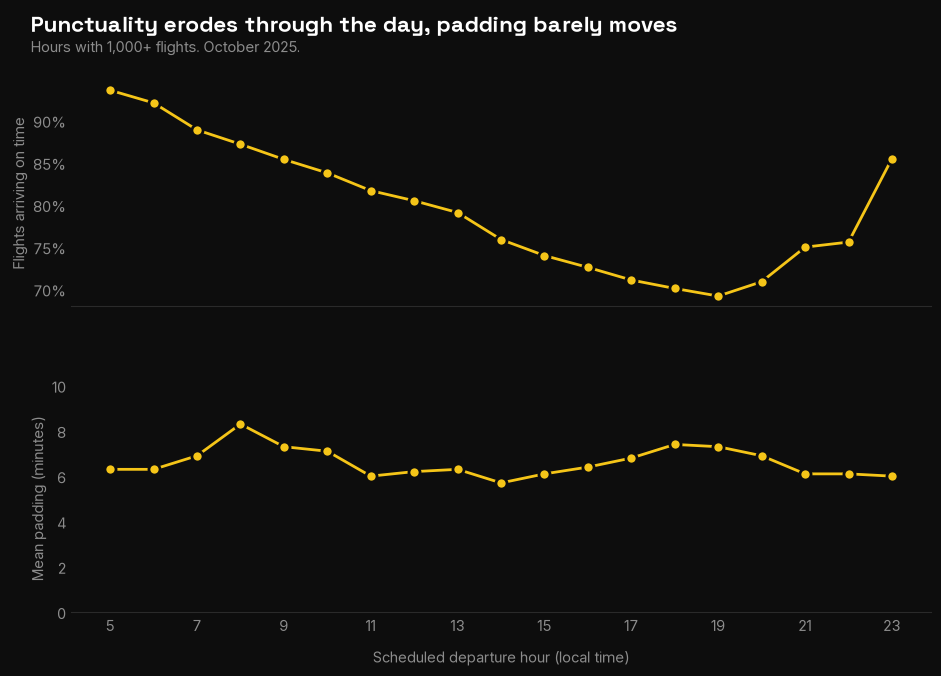

In [11]:
by_hour = con.sql("""
    SELECT (CAST(crs_dep_hhmm AS INT) // 100) % 24      AS hr,
           count(*)                                      AS n,
           round(avg(padding_min), 1)                    AS mean_pad,
           round(100.0 * avg((arr_delay < 15)::INT), 1)  AS ontime_pct
    FROM blk
    GROUP BY 1
    HAVING count(*) >= 1000
    ORDER BY 1
""").df()
display(by_hour.T)

fig, axs = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"hspace": 0.35})
for ax, col, ylabel, fmt in [(axs[0], "ontime_pct", "Flights arriving on time", lambda v, _: f"{v:.0f}%"),
                             (axs[1], "mean_pad", "Mean padding (minutes)", lambda v, _: f"{v:.0f}")]:
    ax.grid(axis="x", visible=False)
    ax.plot(by_hour["hr"], by_hour[col], color=BRAND["yellow"], linewidth=2, marker="o", markersize=8,
            markerfacecolor=BRAND["yellow"], markeredgecolor=BRAND["black"], markeredgewidth=2)
    ax.yaxis.set_major_formatter(FuncFormatter(fmt))
    ax.set_ylabel(ylabel)
    ax.tick_params(length=0)
axs[1].set_ylim(0, 10)
axs[1].set_xticks(range(5, 24, 2))
axs[1].set_xlabel("Scheduled departure hour (local time)", labelpad=10)

fig.text(0.07, 0.96, "Punctuality erodes through the day, padding barely moves", fontsize=16, fontweight="bold",
         fontfamily=TITLE_FONT, ha="left", va="top")
fig.text(0.07, 0.92, "Hours with 1,000+ flights. October 2025.", fontsize=10.5, color=BRAND["grey"], ha="left", va="top")
fig.subplots_adjust(left=0.11, right=0.97, top=0.86, bottom=0.1)

fig.savefig(ROOT / "figures" / "padding_by_hour.png", dpi=150)
plt.show()

### Findings

- Padding differs by airline: Frontier has the highest median (11 min; middle 50% from 7 to 15), Hawaiian (1) and Allegiant (2) the lowest, and most airlines sit between 4 and 8 minutes.
- Padding does not line up with punctuality across airlines: Frontier pads the most and arrives on time 77.6% of the time, while Delta (median 6 min) is the most punctual at 84.0%. Hub mix, weather and other factors are not controlled, so this is not causal.
- On-time rate falls from 93.6% for 5:00 departures to 69.2% for 19:00 departures (almost 25 points), while mean padding stays within 5.7–8.3 minutes, with small peaks at 8:00 and 18:00–19:00.
- Airlines add a little margin at peak hours, but nowhere near enough to offset the daily erosion in punctuality. This pattern is consistent with delay propagating along aircraft rotations through the day (axis 1); that link is not tested here.
- Late departures (23:00, 4,254 flights) show a rebound to 85.5%; with few flights, it should be read with caution.